# 01 — The Complete Training Pipeline: Dataset → DataLoader → Model → Training → Checkpoint

**Overview:** assemble everything from `15`-`21` into one real pipeline: training loop,
validation loop, LR scheduler, checkpointing on best validation score, early stopping, and a
reproducibility check.

**Required libraries:** `torch`.

Connects to: `20_pytorch_models` (the model), `21_pytorch_data` (the data pipeline), Day 2's
`10_ml_optimization` (optimizers/schedulers) and `11_generalization` (early stopping). Leads
to: `23_pytorch_performance`.

### Abbreviations used in this notebook

| Term | Full form | What it is |
|---|---|---|
| **LR** | Learning Rate | Step size of each gradient update. |
| **ReLU** | Rectified Linear Unit | Activation max(0, x). |
| **Adam** | Adaptive Moment Estimation | Optimiser combining momentum with per-parameter adaptive step sizes. |
| **GPU** | Graphics Processing Unit | Massively parallel processor; the main accelerator for deep learning. |

## 0. Environment and reproducibility

In [1]:
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import random
import numpy as np

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

set_seed(42)
print("torch:", torch.__version__)


torch: 2.14.1


## 1. Dataset, DataLoader, and model (reusing 20_pytorch_models / 21_pytorch_data)

In [2]:
class SyntheticClassificationDataset(Dataset):
    def __init__(self, n_samples, n_features, seed):
        g = torch.Generator().manual_seed(seed)
        self.X = torch.randn(n_samples, n_features, generator=g)
        # A slightly noisy, learnable rule -- noise means validation loss WON'T go to ~0,
        # leaving real room to demonstrate early stopping/checkpointing meaningfully.
        noise = torch.randn(n_samples, generator=g) * 0.5
        self.y = ((self.X.sum(dim=1) + noise) > 0).long()

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]

class TwoLayerMLP(nn.Module):
    def __init__(self, in_features, hidden_units, out_classes):
        super().__init__()
        self.layer1 = nn.Linear(in_features, hidden_units)
        self.activation = nn.ReLU()
        self.layer2 = nn.Linear(hidden_units, out_classes)

    def forward(self, x):
        return self.layer2(self.activation(self.layer1(x)))

n_features, hidden_units, out_classes = 10, 16, 2
train_dataset = SyntheticClassificationDataset(400, n_features, seed=1)
val_dataset = SyntheticClassificationDataset(100, n_features, seed=2)

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False)   # never shuffle validation/test data

print(f"train batches: {len(train_loader)}, val batches: {len(val_loader)}")


train batches: 13, val batches: 4


## 2. The training loop

🎯 **Interview Tip:** `optimizer.zero_grad()` at the START of every batch, not the end --
forgetting it is the exact `.grad` accumulation bug from `19_pytorch_autograd`.

In [3]:
def train_one_epoch(model, loader, optimizer, loss_fn):
    model.train()   # enables dropout etc. (none here, but this is always correct practice)
    total_loss = 0.0
    for X_batch, y_batch in loader:
        optimizer.zero_grad()              # 1. zero gradients
        logits = model(X_batch)             # 2. forward pass
        loss = loss_fn(logits, y_batch)     # 3. compute loss
        loss.backward()                     # 4. backward pass
        optimizer.step()                    # 5. optimizer step
        total_loss += loss.item() * len(X_batch)
    return total_loss / len(loader.dataset)

print("train_one_epoch defined.")


train_one_epoch defined.


## 3. The validation loop

⚠️ **Common Mistake:** forgetting `model.eval()` and/or `torch.no_grad()` here -- both matter,
for different reasons (dropout correctness vs wasted memory/compute).

In [4]:
@torch.no_grad()
def evaluate(model, loader, loss_fn):
    model.eval()   # disables dropout etc.
    total_loss, correct = 0.0, 0
    for X_batch, y_batch in loader:
        logits = model(X_batch)
        loss = loss_fn(logits, y_batch)
        total_loss += loss.item() * len(X_batch)
        correct += (logits.argmax(dim=1) == y_batch).sum().item()
    return total_loss / len(loader.dataset), correct / len(loader.dataset)

print("evaluate defined.")


evaluate defined.


## 4. Full pipeline: training + validation + LR scheduler + checkpointing + early stopping

In [5]:
set_seed(42)
model = TwoLayerMLP(n_features, hidden_units, out_classes)
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)
scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=10, gamma=0.5)
loss_fn = nn.CrossEntropyLoss()

CHECKPOINT_PATH = "best_model_checkpoint.pt"
best_val_loss = float("inf")
patience, epochs_since_improvement = 8, 0
train_losses, val_losses, val_accuracies, learning_rates = [], [], [], []

for epoch in range(60):
    train_loss = train_one_epoch(model, train_loader, optimizer, loss_fn)
    val_loss, val_acc = evaluate(model, val_loader, loss_fn)
    scheduler.step()

    train_losses.append(train_loss)
    val_losses.append(val_loss)
    val_accuracies.append(val_acc)
    learning_rates.append(optimizer.param_groups[0]["lr"])

    if val_loss < best_val_loss - 1e-4:
        best_val_loss = val_loss
        epochs_since_improvement = 0
        torch.save({
            "epoch": epoch,
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "val_loss": val_loss,
        }, CHECKPOINT_PATH)
    else:
        epochs_since_improvement += 1
        if epochs_since_improvement >= patience:
            print(f"early stopping at epoch {epoch} (best val_loss={best_val_loss:.4f})")
            break

print(f"\nfinal train_loss={train_losses[-1]:.4f}, val_loss={val_losses[-1]:.4f}, val_acc={val_accuracies[-1]:.3f}")
print(f"best val_loss seen: {best_val_loss:.4f}")
assert val_losses[-1] < val_losses[0]   # meaningful learning happened


early stopping at epoch 15 (best val_loss=0.1263)

final train_loss=0.0881, val_loss=0.1383, val_acc=0.940
best val_loss seen: 0.1263


## 5. Plot training curves

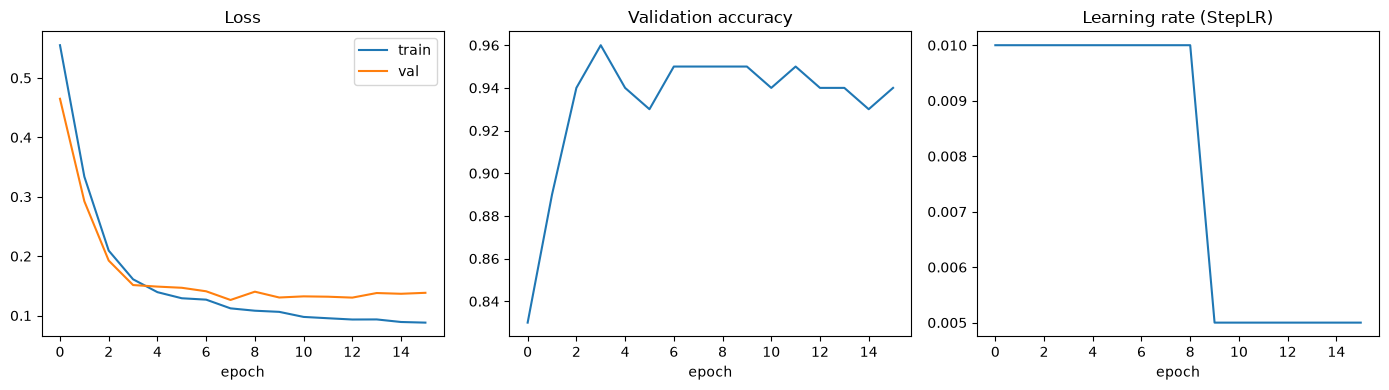

In [6]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
axes[0].plot(train_losses, label="train"); axes[0].plot(val_losses, label="val")
axes[0].set_title("Loss"); axes[0].set_xlabel("epoch"); axes[0].legend()
axes[1].plot(val_accuracies)
axes[1].set_title("Validation accuracy"); axes[1].set_xlabel("epoch")
axes[2].plot(learning_rates)
axes[2].set_title("Learning rate (StepLR)"); axes[2].set_xlabel("epoch")
plt.tight_layout(); plt.show()


## 6. Reload the checkpoint and verify it reproduces the best validation score

In [7]:
checkpoint = torch.load(CHECKPOINT_PATH, weights_only=False)
restored_model = TwoLayerMLP(n_features, hidden_units, out_classes)
restored_model.load_state_dict(checkpoint["model_state_dict"])

restored_val_loss, restored_val_acc = evaluate(restored_model, val_loader, loss_fn)
print(f"checkpoint was saved at epoch {checkpoint['epoch']} with val_loss={checkpoint['val_loss']:.4f}")
print(f"reloaded model's val_loss: {restored_val_loss:.4f} (should match exactly)")

assert abs(restored_val_loss - checkpoint["val_loss"]) < 1e-6

import os
os.remove(CHECKPOINT_PATH)   # cleanup


checkpoint was saved at epoch 7 with val_loss=0.1263
reloaded model's val_loss: 0.1263 (should match exactly)


## 7. Reproducibility: same seed -> same results

💡 **Key Idea:** this is why `set_seed()` was called before building the model -- two runs
with the same seed and same code should produce IDENTICAL results, which is essential for
debugging and for fair hyperparameter comparisons (Day 2's `14_hyperparameter_tuning`).

In [8]:
def run_one_epoch_from_scratch(seed):
    set_seed(seed)
    model = TwoLayerMLP(n_features, hidden_units, out_classes)
    optimizer = torch.optim.Adam(model.parameters(), lr=0.01)
    loss_fn = nn.CrossEntropyLoss()
    train_loss = train_one_epoch(model, train_loader, optimizer, loss_fn)
    return train_loss, model.layer1.weight.clone()

loss_run_a, weights_run_a = run_one_epoch_from_scratch(seed=123)
loss_run_b, weights_run_b = run_one_epoch_from_scratch(seed=123)   # same seed

print(f"run A loss: {loss_run_a:.6f}")
print(f"run B loss: {loss_run_b:.6f}")
print(f"weights identical: {torch.equal(weights_run_a, weights_run_b)}")

assert loss_run_a == loss_run_b
assert torch.equal(weights_run_a, weights_run_b)


run A loss: 0.674534
run B loss: 0.674534
weights identical: True


## 8. Connection to what's next

This is the same pipeline used to fine-tune any model in this workspace's `llm-fine-tuning/`
curriculum — more parameters, more data, usually a GPU, but the same ten steps.
`23_pytorch_performance` covers how to make this pipeline fast and memory-efficient at scale
(mixed precision, gradient accumulation, profiling).

## 9. Interview questions
1. Walk through every step between `optimizer.zero_grad()` and `optimizer.step()`, and what each one does.
2. Why is `val_loader` never shuffled, while `train_loader` always is?
3. Why checkpoint using validation loss rather than training loss?
4. What's the point of a reproducibility check like the one in section 7?
5. Why does the scheduler get `.step()`-ed once per epoch here rather than once per batch?

## 10. Exercises
1. Change the scheduler to `CosineAnnealingLR` and compare the resulting loss curve to `StepLR`'s.
2. Add gradient clipping (`torch.nn.utils.clip_grad_norm_`) to the training loop and explain when it would matter.
3. Modify the checkpoint to also save `scheduler.state_dict()`, and verify the scheduler's state is restored correctly after reloading.

## 11. Summary

✅ The complete training pipeline integrates every piece from `15`-`21`: data loading, a
model, a loss, backpropagation, an optimizer, a scheduler, validation, checkpointing, and
early stopping. This is exactly the pipeline used (at larger scale) to fine-tune real models.
Next: `23_pytorch_performance`.